In [1]:
import os
import requests
import pandas as pd
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from shapely.geometry import Point

In [2]:
load_dotenv()

NOBIL_API_KEY = os.getenv("NOBIL_API_KEY")

In [4]:
center = (60.39299, 5.32415)  # lat, lon
radius = 3000  # meter

G = ox.graph_from_point(
    center,
    dist=radius,
    network_type="drive"
)

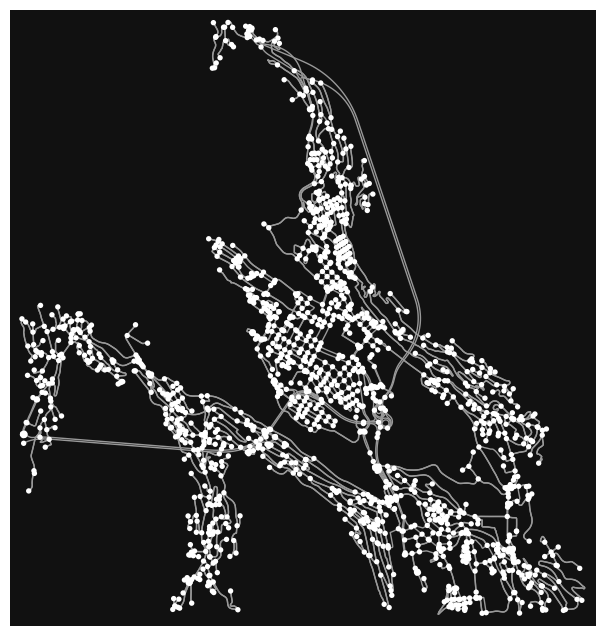

In [6]:
fig, ax = ox.plot_graph(G)

In [7]:
url = "https://nobil.no/api/server/search.php"

params = {
    "apikey": NOBIL_API_KEY,
    "apiversion": "3",
    "action": "search",
    "type": "rectangle",
    "northeast": "(60.42, 5.38)",
    "southwest": "(60.36, 5.26)",
    "limit": "100",
    "format": "json"
}

response = requests.get(url, params=params)
response.raise_for_status()

data = response.json()

In [8]:
type(data), len(data)

(dict, 4)

In [9]:
data.keys() if isinstance(data, dict) else None

dict_keys(['Provider', 'Rights', 'apiver', 'chargerstations'])

In [10]:
data

{'Provider': 'NOBIL.no',
 'Rights': 'Creative Commons Attribution 4.0 International License',
 'apiver': '3',
 'chargerstations': [{'csmd': {'id': 75204,
    'name': 'Taxi - Erleveien',
    'ocpidb_mapping_stasjon_id': 'NO#BKK#BAYXQW2SSV9XC',
    'Street': 'Erleveien',
    'House_number': '22',
    'Zipcode': '5097',
    'City': 'BERGEN',
    'Municipality_ID': '4601',
    'Municipality': 'BERGEN',
    'County_ID': '46',
    'County': 'Vestland',
    'Description_of_location': None,
    'Owned_by': 'Eviny',
    'Operator': 'Eviny',
    'Number_charging_points': 8,
    'Position': '(60.361268,5.368839)',
    'Image': 'no.image.svg',
    'User_comment': None,
    'Contact_info': None,
    'Created': '2025-12-23 04:00:09',
    'Updated': '2026-06-26 18:02:16',
    'Station_status': 1,
    'Land_code': 'NOR',
    'International_id': 'NOR_75204'},
   'attr': {'st': {'24': {'attrtypeid': '24',
      'attrname': 'Open 24h',
      'attrvalid': '1',
      'trans': 'Yes',
      'attrval': '1'},
